# Autoencoders con Keras

https://blog.keras.io/building-autoencoders-in-keras.html

In [1]:
from keras.layers import Input, Dense, Concatenate, Conv2D, MaxPooling2D, UpSampling2D, AveragePooling2D
from keras.models import Model
from keras import regularizers

import matplotlib.pyplot as plt


In [35]:
# dimension de dominio intermedio
encoding_dim = 1

input_img = Input(shape=(28,28,1))
# ENCODER
x1 = Conv2D(encoding_dim,5,padding = 'SAME')(input_img) #activation='relu'
encoded = MaxPooling2D(2)(x1)
# DECODER

x2 = UpSampling2D(2, interpolation="bilinear")(encoded)
decoded = Conv2D(1,5,padding = 'SAME',activation='relu')(x2) # activation='sigmoid'

# AUTOENCODER
autoencoder = Model(input_img, decoded)
#autoencoder = Model(input_img, concat)

In [36]:
autoencoder.summary()

Model: "functional_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)           │ (None, 28, 28, 1)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_16 (Conv2D)                   │ (None, 28, 28, 1)           │              26 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 14, 14, 1)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ up_sampling2d_8 (UpSampling2D)       │ (None, 28, 28, 1)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_17 (Conv2D)                   │ (None, 28, 28, 1)           │              26 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 52 (208.00 B)

 Trainable params: 52 (208.00 B)

 Non-trainable params: 0 (0.00 B)

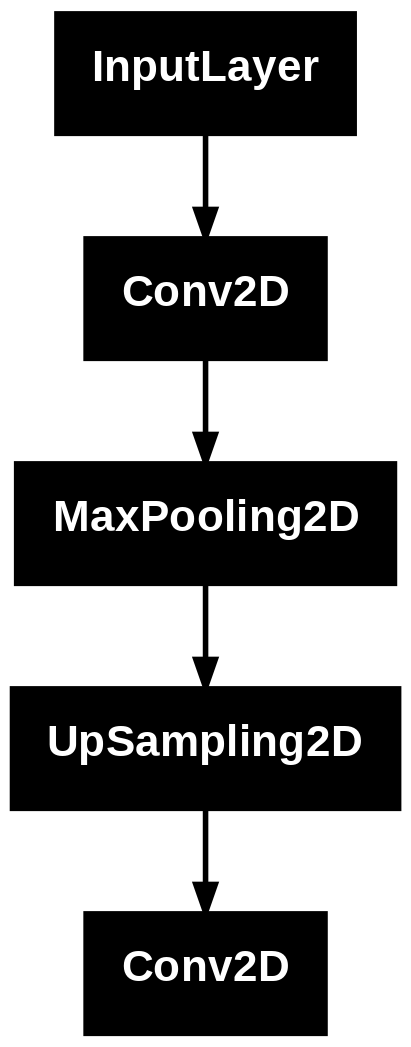

In [37]:
import keras
keras.utils.plot_model(autoencoder)

In [22]:
autoencoder.summary()

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)           │ (None, 28, 28, 1)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_10 (Conv2D)                   │ (None, 28, 28, 10)          │             100 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ average_pooling2d_4                  │ (None, 14, 14, 10)          │               0 │
│ (AveragePooling2D)                   │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_11 (Conv2D)                   │ (None, 14, 14, 5)           │             455 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ average_pooling2d_5                  │ (None, 7, 7, 5)             │               0 │
│ (AveragePooling2D)                   │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ up_sampling2d_5 (UpSampling2D)       │ (None, 14, 14, 5)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_12 (Conv2D)                   │ (None, 14, 14, 10)          │             460 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ up_sampling2d_6 (UpSampling2D)       │ (None, 28, 28, 10)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_13 (Conv2D)                   │ (None, 28, 28, 1)           │              91 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,106 (4.32 KB)

 Trainable params: 1,106 (4.32 KB)

 Non-trainable params: 0 (0.00 B)

In [38]:
# Modelo para el encoder
encoder = Model(input_img, encoded)
encoder.summary()

Model: "functional_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)           │ (None, 28, 28, 1)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_16 (Conv2D)                   │ (None, 28, 28, 1)           │              26 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 14, 14, 1)           │               0 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 26 (104.00 B)

 Trainable params: 26 (104.00 B)

 Non-trainable params: 0 (0.00 B)

In [39]:
# Otra forma de hacer el decoder
decoder = Model(encoded, decoded)
decoder.summary()

Model: "functional_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ keras_tensor_39CLONE (InputLayer)    │ (None, 14, 14, 1)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ up_sampling2d_8 (UpSampling2D)       │ (None, 28, 28, 1)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_17 (Conv2D)                   │ (None, 28, 28, 1)           │              26 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 26 (104.00 B)

 Trainable params: 26 (104.00 B)

 Non-trainable params: 0 (0.00 B)

In [40]:
autoencoder.compile(optimizer='adam', loss='mse',metrics=['mse','mae'])

In [41]:
# DATOS
from keras.datasets import mnist
import numpy as np
(x_train, _), (x_test, _) = mnist.load_data()

In [42]:
x_train.shape

(60000, 28, 28)

In [43]:

x_train = x_train.astype('float32') / 255.
x_test = x_test.astype('float32') / 255.
x_train = x_train.reshape((x_train.shape[0],x_train.shape[1],x_train.shape[2],1))
x_test = x_test.reshape((x_test.shape[0],x_test.shape[1],x_test.shape[2],1))
print(x_train.shape)
print(x_test.shape)

(60000, 28, 28, 1)
(10000, 28, 28, 1)


In [44]:
# ENTRENAMIENTO
hist = autoencoder.fit(x_train, x_train,
                epochs=20,
                batch_size=256,
                shuffle=True,
                validation_split=0.1)

Epoch 1/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - loss: 0.0495 - mae: 0.1038 - mse: 0.0495 - val_loss: 0.0174 - val_mae: 0.0559 - val_mse: 0.0174
Epoch 2/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0161 - mae: 0.0528 - mse: 0.0161 - val_loss: 0.0143 - val_mae: 0.0487 - val_mse: 0.0143
Epoch 3/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0138 - mae: 0.0475 - mse: 0.0138 - val_loss: 0.0127 - val_mae: 0.0454 - val_mse: 0.0127
Epoch 4/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0123 - mae: 0.0446 - mse: 0.0123 - val_loss: 0.0115 - val_mae: 0.0433 - val_mse: 0.0115
Epoch 5/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0113 - mae: 0.0428 - mse: 0.0113 - val_loss: 0.0108 - val_mae: 0.0419 - val_mse: 0.0108
Epoch 6/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0107 - mae: 0.0417 - mse: 0.0107 - val_loss: 0.0103 - val_mae: 0.0412 - val_mse: 0.0103
Epoch 7/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0103 - mae: 0.0410 - mse: 0.0103 - va

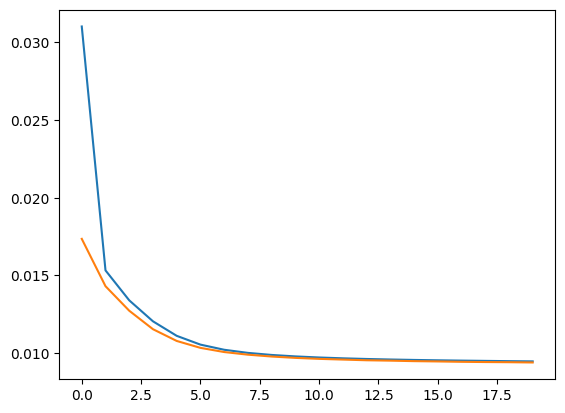

In [45]:
plt.plot(hist.history['loss'])
plt.plot(hist.history['val_loss'])

In [46]:
# APLICACION EN TEST
encoded_imgs = encoder.predict(x_test)
decoded_imgs = decoder.predict(encoded_imgs)

# Mismo que
# decoded_imgs = autoencoder.predict(x_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [47]:
autoencoder.evaluate(x_test,x_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0091 - mae: 0.0381 - mse: 0.0091


[0.00943844672292471, 0.00943844672292471, 0.03901863098144531]

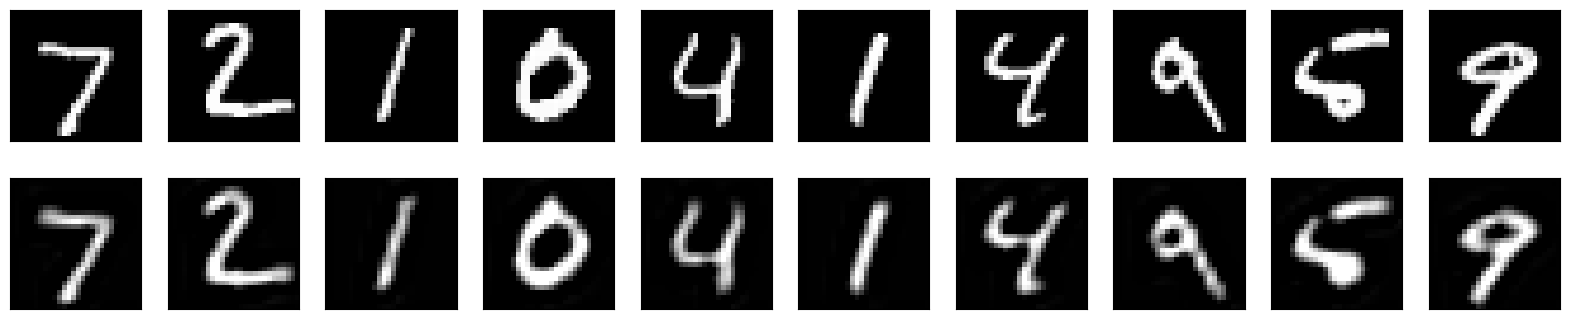

In [48]:

import matplotlib.pyplot as plt

n = 10
plt.figure(figsize=(20, 4))
for i in range(n):
    # display original
    ax = plt.subplot(2, n, i + 1)
    plt.imshow(x_test[i].reshape(28, 28),vmin=0,vmax=1)
    plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

    # display reconstruccion
    ax = plt.subplot(2, n, i + 1 + n)
    plt.imshow(decoded_imgs[i].reshape(28, 28),vmin=0,vmax=1)
    plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)
plt.show()

# Limpieza de ruido

In [54]:
# Creamos datos ruidosos
x_test_nois = x_test + 0.2*np.random.randn(x_test.shape[0],x_test.shape[1],x_test.shape[2],1)
encoded_imgs = encoder.predict(x_test_nois)
decoded_imgs = decoder.predict(encoded_imgs)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


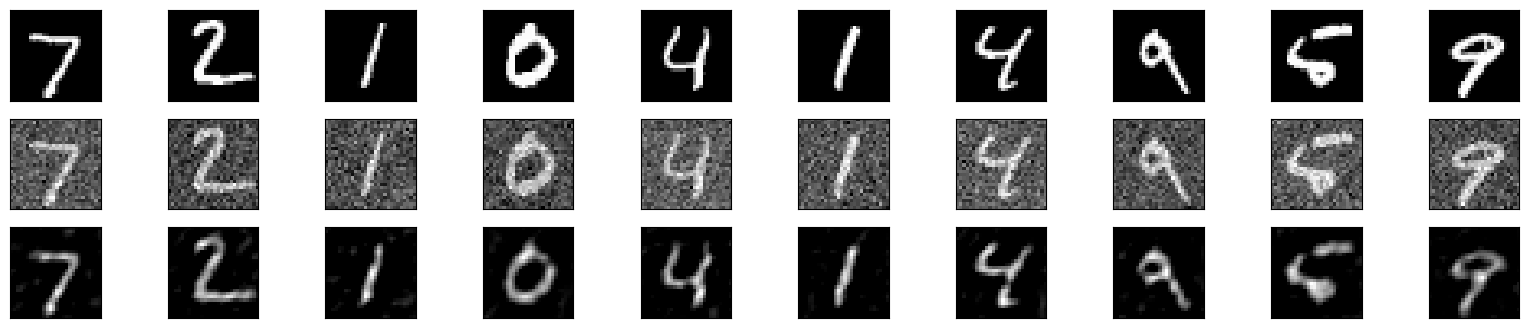

In [55]:
import matplotlib.pyplot as plt

n = 10
plt.figure(figsize=(20, 4))
for i in range(n):
    # Originales
    ax = plt.subplot(3, n, i + 1)
    plt.imshow(x_test[i])
    plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

    # Ruidosos
    ax = plt.subplot(3, n, i + 1 + n)
    plt.imshow(x_test_nois[i])
    plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

    # Reconstruccion
    ax = plt.subplot(3, n, i + 1 + 2*n)
    plt.imshow(decoded_imgs[i])
    plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)
plt.show()

# Detección de anomalias

## Ejemplo con los datos ruidosos

In [56]:
import numpy as np
# calculamos el error en los datos normales y ruidosos

ncoded_imgs = encoder.predict(x_test_nois)
x_test_nois_pred = decoder.predict(encoded_imgs)

error_nois = np.mean(np.abs(x_test_nois-x_test_nois_pred)**2,tuple(range(1, x_test_nois.ndim)))


x_test_pred = autoencoder.predict(x_test)

error_tes = np.mean(np.abs(x_test-x_test_pred)**2,tuple(range(1, x_test_pred.ndim)))


313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


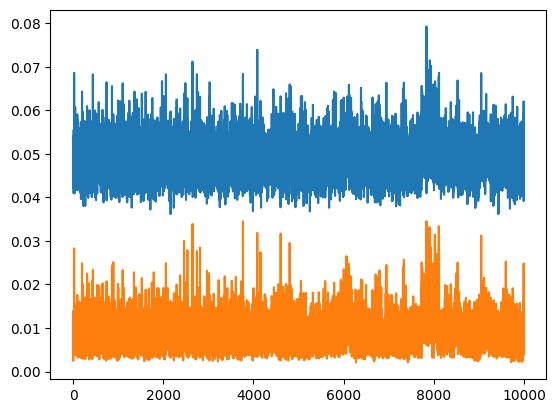

In [57]:
import matplotlib.pyplot as plt
%matplotlib inline
plt.figure
plt.plot(error_nois)
plt.plot(error_tes)


## Ejemplo inventado

In [114]:
import numpy as np

X_test_anom = x_test.copy()


#Distintos tipos de anomalias

# Zero
#X_test_anom[1000,:] = np.ones((1,X_test_anom.shape[1]))*0

# Max
#X_test_anom[1000,:] = np.ones((1,X_test_anom.shape[1]))*x_test.max()

# Negativo
#X_test_anom[1000,:] = np.ones((1,X_test_anom.shape[1]))-X_test_anom[1000,:]

# Multiplicado
#X_test_anom[1000,:] = 1.5*X_test_anom[1000,:]

# Ruido
#X_test_anom[1000,:] = X_test_anom[1000,:] + 0.5*np.random.randn(1,X_test_anom.shape[1])

# Patch
X_test_anom[1000,2:10,2:25,0] = 1

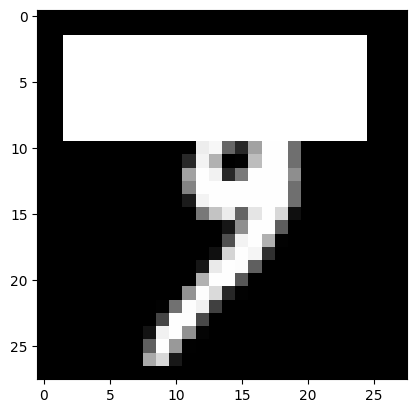

In [115]:
plt.imshow(X_test_anom[1000,:])

In [116]:
X_test_anom.shape

(10000, 28, 28, 1)

In [117]:

# calculamos el error en los datos reconstruidos

X_test_anom_pred = autoencoder.predict(X_test_anom)

error_tes = np.mean(np.abs(X_test_anom-X_test_anom_pred)**2,axis=(1,2,3))


313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


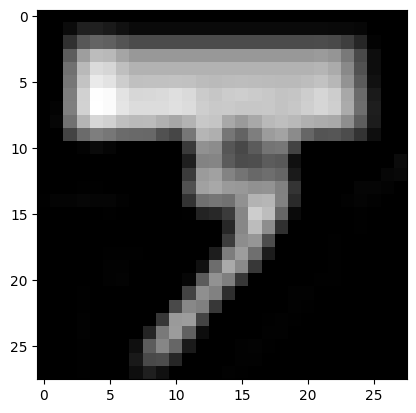

In [118]:
plt.imshow(X_test_anom_pred[1000,:])

In [119]:
error_tes.shape

(10000,)

In [120]:
 error_tes[1000]

0.034234814

In [121]:
error_tes[1]

0.0063956343

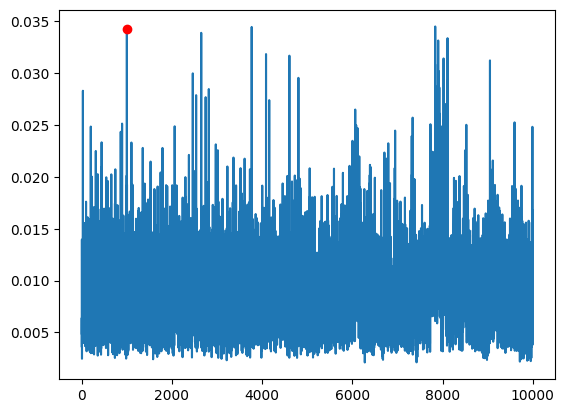

In [123]:
import matplotlib.pyplot as plt
%matplotlib inline
plt.figure
plt.plot(error_tes)
plt.plot(1000,error_tes[1000],'ro')
